# Notebook 13 — Fixed LSTM Baseline: Explain, Train, Validate

**Project:** Sri Lanka Dengue Disease Prediction | **Previous notebook:** 12 — Time-Series Splitting and Scaling

**Research question:** How accurately can a **fixed-architecture LSTM** predict district dengue cases **one month ahead**, using the preceding six months of known dengue/weather predictors?

**In this notebook:** load Notebook 12 training and validation sequences; explain the input/target; train one reproducible LSTM; compare predictions to observed cases; inspect errors and save a frozen baseline.

**Not in this notebook:** hyperparameter optimization, final test scoring, or 2024 prediction inspection. **Do not load `weather_only_test.npz` here.**

> The dengue target comes from day-proportionally allocated weekly reports and can be fractional. These are **estimated monthly case totals**, not independently observed daily counts.

### What to learn
1. Why the LSTM receives a three-dimensional tensor `(samples, months, features)`.
2. What its memory and gates do (conceptually).
3. Why we train on `log1p(cases)` but report errors in **case units**.
4. How early stopping works without looking at 2024.
5. How to interpret validation MAE, RMSE and district-level errors.


## Step 0 — Install requirements (once, in your VS Code PowerShell terminal)

Activate `.venv` and run:

```powershell
python -m pip install tensorflow pandas numpy scikit-learn matplotlib ipython
```

Then restart the notebook kernel. **Do not paste `pip install` into the Python code cell.** TensorFlow may require a supported Python/platform version; use a compatible environment if installation fails. The notebook checks TensorFlow availability before training.

**Runtime note:** CPU training is supported but may take several minutes. The first run trains only one model.


## Step 1 — Find your project and configure reproducibility

We use the same directory structure as Notebook 12. A fixed random seed reduces run-to-run variation, but exact results may still differ across hardware or TensorFlow versions.

In [1]:
from pathlib import Path
import json, os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error
from IPython.display import display

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / "data" / "final" / "model_inputs").is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Cannot find data/final/model_inputs. Run Notebook 12 and open your Dengue_Project folder.")
INPUT_DIR = PROJECT_ROOT / "data" / "final" / "model_inputs"
MODELS_DIR = PROJECT_ROOT / "models"
METRICS_DIR = PROJECT_ROOT / "results" / "metrics"
TABLES_DIR = PROJECT_ROOT / "results" / "tables"
FIGURES_DIR = PROJECT_ROOT / "results" / "figures"
for d in [MODELS_DIR, METRICS_DIR, TABLES_DIR, FIGURES_DIR]: d.mkdir(parents=True, exist_ok=True)
VARIANT = "weather_only"  # Primary experiment: 2010–2023 training/validation; no population backfilling.
print("Project root:", PROJECT_ROOT)
print("Experiment:", VARIANT)


Project root: d:\Dengue_Project
Experiment: weather_only


## Step 2 — Load TensorFlow

**LSTM** stands for *Long Short-Term Memory*. It is a recurrent neural network that can learn how patterns change over time. At each monthly step, the cell updates an internal memory using **input**, **forget**, and **output** gates.

The model sees six consecutive feature months, e.g. **January–June**, and learns to predict **July** dengue cases.

In [2]:
try:
    import tensorflow as tf
except ImportError as exc:
    raise ImportError("TensorFlow is not installed in this notebook kernel. Run: python -m pip install tensorflow") from exc

tf.keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPUs detected:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPUs detected: []


## Step 3 — Load only training and validation arrays

Notebook 12 saved four arrays per partition:

- `X`: standardized predictors, shape `(n_samples, 6, n_features)`.
- `y_log1p`: `log(1 + cases)`, used as the training target.
- `y_raw`: original dengue case totals, used for interpretable metrics.
- `feature_names`: the **exact order** of columns used in the LSTM.

The matching metadata CSV maps every sample to a **district** and a **target month**. Loading the test set here would make accidental test leakage easier, so we deliberately do not do it.

In [3]:
def load_partition(variant, partition):
    file = INPUT_DIR / f"{variant}_{partition}.npz"
    meta_file = INPUT_DIR / f"{variant}_{partition}_metadata.csv"
    if not file.exists() or not meta_file.exists():
        raise FileNotFoundError(f"Missing {file.name} or metadata. Run Notebook 12 first.")
    with np.load(file, allow_pickle=False) as data:
        X = data["X"].astype(np.float32)
        y_raw = data["y_raw"].astype(np.float32)
        y_log = data["y_log1p"].astype(np.float32)
        names = data["feature_names"].tolist()
    meta = pd.read_csv(meta_file, parse_dates=["target_date", "feature_date", "sequence_start_date"])
    assert X.ndim == 3 and len(X) == len(y_raw) == len(y_log) == len(meta)
    assert np.isfinite(X).all() and np.isfinite(y_log).all()
    assert np.allclose(np.log1p(y_raw.astype(float)), y_log.astype(float), atol=1e-5)
    assert (meta["partition"] == partition).all()
    assert np.allclose(meta["target_dengue_cases"].to_numpy(), y_raw, atol=1e-3)
    return X, y_raw, y_log, names, meta

X_train, y_train_raw, y_train_log, names_train, meta_train = load_partition(VARIANT, "train")
X_val, y_val_raw, y_val_log, names_val, meta_val = load_partition(VARIANT, "validation")
assert names_train == names_val, "Feature order differs between train and validation!"
assert X_train.shape[1] == X_val.shape[1] == 6
assert X_train.shape[2] == X_val.shape[2] == len(names_train)
assert meta_train["target_date"].max() <= pd.Timestamp("2021-12-01")
assert meta_val["target_date"].between("2022-01-01", "2023-12-01").all()
print("Training X:", X_train.shape, "target:", y_train_log.shape)
print("Validation X:", X_val.shape, "target:", y_val_log.shape)
print("First 10 features:", names_train[:10])


Training X: (3300, 6, 33) target: (3300,)
Validation X: (600, 6, 33) target: (600,)
First 10 features: ['dengue_cases', 'dengue_cases_lag1', 'dengue_cases_lag2', 'dengue_cases_lag3', 'dengue_cases_lag6', 'dengue_cases_roll3_mean', 'dengue_cases_roll6_mean', 'temperature_mean_c', 'humidity_mean_percent', 'rainfall_total_mm']


## Step 4 — Understand one LSTM training example

Imagine `X_train[0]` is a **6 × 33** table (six months and 33 predictors). Each row is one month; each column is one engineered predictor such as lagged dengue counts, rainfall, humidity or seasonal encoding.

The target `y_train_raw[0]` is the **next month's** dengue total for that district. `y_train_log[0]` is the same target on the log scale. **The future target is not an input column.**

Why log-transform? Dengue counts can be highly skewed: a few epidemic months may contain far more cases than typical months. `log1p` reduces the influence of very large values during optimization. We will **reverse** this transform before evaluating the model.

In [4]:
example = pd.DataFrame(X_train[0], columns=names_train)
example.index = [f"Month {i+1}" for i in range(len(example))]
display(example.iloc[:, :min(8, len(names_train))].round(3))
print("Example district:", meta_train.iloc[0]["administrative_district"])
print("History:", meta_train.iloc[0]["sequence_start_date"].date(), "to", meta_train.iloc[0]["feature_date"].date())
print("Prediction target month:", meta_train.iloc[0]["target_date"].date())
print("Actual next-month cases:", round(float(y_train_raw[0]), 2))
print("Training label log1p(cases):", round(float(y_train_log[0]), 4))


,dengue_cases,dengue_cases_lag1,dengue_cases_lag2,dengue_cases_lag3,dengue_cases_lag6,dengue_cases_roll3_mean,dengue_cases_roll6_mean,temperature_mean_c
Month 1,-0.313,-0.369,-0.357,-0.299,-0.107,-0.383,-0.336,1.207
Month 2,-0.339,-0.314,-0.369,-0.358,-0.087,-0.376,-0.388,1.039
Month 3,-0.363,-0.340,-0.314,-0.369,-0.215,-0.374,-0.420,0.631
Month 4,-0.363,-0.364,-0.340,-0.314,-0.302,-0.393,-0.433,0.557
Month 5,-0.334,-0.364,-0.364,-0.340,-0.361,-0.391,-0.428,-0.106
Month 6,-0.358,-0.334,-0.364,-0.364,-0.372,-0.389,-0.426,-0.502


Example district: Ampara
History: 2010-07-01 to 2010-12-01
Prediction target month: 2011-01-01
Actual next-month cases: 7.0
Training label log1p(cases): 2.0794


## Step 5 — Define a **fixed** LSTM architecture

The architecture below remains unchanged during the baseline experiment:

| Layer | Purpose |
|---|---|
| LSTM, 32 units | Learn temporal patterns across six months |
| Dense, 16 units, ReLU | Combine learned temporal signals |
| Dropout, 0.20 | Regularization during training |
| Dense, 1 output | Predict `log1p(next-month dengue cases)` |

**Loss = mean squared error in log space.** **Optimizer = Adam.**

Notebook 14 will keep the *same layer topology and number of units*, but investigate **training hyperparameters** (learning rate, dropout rate, batch size) using Grey Wolf Optimization. This separates architecture design from hyperparameter search.

In [5]:
CONFIG = {
    "variant": VARIANT,
    "random_seed": SEED,
    "sequence_length": int(X_train.shape[1]),
    "n_features": int(X_train.shape[2]),
    "lstm_units": 32,
    "dense_units": 16,
    "dropout": 0.20,
    "learning_rate": 0.001,
    "batch_size": 32,
    "max_epochs": 40,
    "early_stopping_patience": 6,
    "loss": "mse_on_log1p_cases",
    "target_transform": "log1p",
    "selection_data": "validation_2022_2023_only",
}

def build_fixed_lstm(input_shape, learning_rate=0.001, dropout=0.20):
    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=input_shape),
        tf.keras.layers.LSTM(32),
        tf.keras.layers.Dense(16, activation="relu"),
        tf.keras.layers.Dropout(float(dropout)),
        tf.keras.layers.Dense(1),
    ])
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=float(learning_rate)), loss="mse")
    return model

model = build_fixed_lstm(X_train.shape[1:], CONFIG["learning_rate"], CONFIG["dropout"])
model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 32)             │         8,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,993 (35.13 KB)

 Trainable params: 8,993 (35.13 KB)

 Non-trainable params: 0 (0.00 B)

## Step 6 — Train using training labels; monitor validation loss

During training, the network updates its weights using **training batches only**. After each epoch, validation loss is measured to assess generalization. **Early stopping** stops training if validation loss fails to improve for six epochs and restores the best validation-loss weights.

Using validation labels for early stopping is allowed; using **2024 test labels** is not.

We do not shuffle the individual sequences in this baseline (`shuffle=False`) to keep the procedure simple and reproducible. Each sequence already contains ordered months; samples are separate windows, not one continuous recurrent state.

In [6]:
callbacks = [tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=CONFIG["early_stopping_patience"],
    restore_best_weights=True, mode="min"
)]
history = model.fit(
    X_train, y_train_log,
    validation_data=(X_val, y_val_log),
    epochs=CONFIG["max_epochs"], batch_size=CONFIG["batch_size"],
    callbacks=callbacks, verbose=2, shuffle=False,
)
print("Epochs completed:", len(history.history["loss"]))
print("Best validation MSE (log scale):", min(history.history["val_loss"]))


Epoch 1/40
104/104 - 2s - 15ms/step - loss: 10.1737 - val_loss: 4.9427
Epoch 2/40
104/104 - 0s - 2ms/step - loss: 3.3618 - val_loss: 2.8112
Epoch 3/40
104/104 - 0s - 2ms/step - loss: 2.4111 - val_loss: 2.0531
Epoch 4/40
104/104 - 0s - 3ms/step - loss: 2.1688 - val_loss: 2.0480
Epoch 5/40
104/104 - 0s - 2ms/step - loss: 2.0410 - val_loss: 1.7141
Epoch 6/40
104/104 - 0s - 2ms/step - loss: 1.8683 - val_loss: 1.5717
Epoch 7/40
104/104 - 0s - 2ms/step - loss: 1.6944 - val_loss: 1.4768
Epoch 8/40
104/104 - 0s - 2ms/step - loss: 1.6558 - val_loss: 1.2922
Epoch 9/40
104/104 - 0s - 2ms/step - loss: 1.6754 - val_loss: 1.2995
Epoch 10/40
104/104 - 0s - 2ms/step - loss: 1.6078 - val_loss: 1.2399
Epoch 11/40
104/104 - 0s - 2ms/step - loss: 1.5673 - val_loss: 1.0675
Epoch 12/40
104/104 - 0s - 2ms/step - loss: 1.4393 - val_loss: 1.0280
Epoch 13/40
104/104 - 0s - 2ms/step - loss: 1.4021 - val_loss: 1.0284
Epoch 14/40
104/104 - 0s - 2ms/step - loss: 1.3867 - val_loss: 0.8520
Epoch 15/40
104/104 - 0s - 

## Step 7 — Plot training and validation loss

**Interpretation guide:**
- Both curves falling: the model is learning.
- Training loss keeps falling while validation rises: possible overfitting.
- Both curves remain high: possible underfitting, poor features or difficult forecasting.
- A lower log-scale loss is **not** the same thing as a lower case-count RMSE.


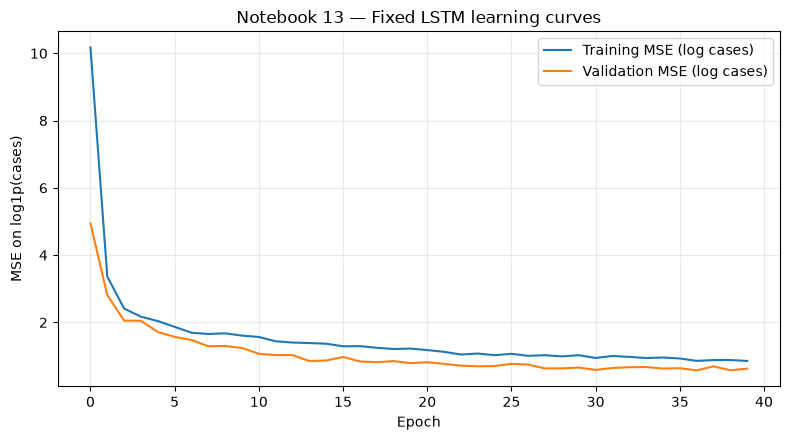

In [7]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(history.history["loss"], label="Training MSE (log cases)")
ax.plot(history.history["val_loss"], label="Validation MSE (log cases)")
ax.set(xlabel="Epoch", ylabel="MSE on log1p(cases)", title="Notebook 13 — Fixed LSTM learning curves")
ax.legend(); ax.grid(alpha=0.25)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "notebook13_fixed_lstm_learning_curves.png", dpi=160)
plt.show()


## Step 8 — Convert predictions to dengue cases

The output of the final Dense layer is a real number on the **log1p scale**. We convert it using `expm1`. Since a negative number of dengue cases is impossible, predictions are clipped to zero **after** inverse transformation.

**Metrics (validation only):**

- **MAE:** average absolute prediction error in case units.
- **RMSE:** square root of average squared error; penalizes large mistakes more strongly.
- **sMAPE:** optional percentage-like metric, unstable near zero; report with caution.

The 2024 test set remains unopened.

In [8]:
def log_predictions_to_cases(predicted_log):
    values = np.asarray(predicted_log, dtype=np.float64).reshape(-1)
    # Limit extreme numerical overflow without changing ordinary values.
    return np.maximum(0.0, np.expm1(np.clip(values, -20.0, 20.0)))

def case_metrics(actual, predicted):
    actual = np.asarray(actual, dtype=float).reshape(-1)
    predicted = np.asarray(predicted, dtype=float).reshape(-1)
    return {"MAE_cases": float(mean_absolute_error(actual, predicted)),
            "RMSE_cases": float(np.sqrt(mean_squared_error(actual, predicted))),
            "n_samples": int(len(actual))}

val_pred_log = model.predict(X_val, verbose=0).reshape(-1)
val_pred_cases = log_predictions_to_cases(val_pred_log)
validation_metrics = case_metrics(y_val_raw, val_pred_cases)
print("Validation performance (2022–2023 only):", validation_metrics)


Validation performance (2022–2023 only): {'MAE_cases': 89.07862766408147, 'RMSE_cases': 177.53212504937076, 'n_samples': 600}


## Step 9 — Inspect district-level and month-level errors

An overall metric can hide poor performance in outbreak-prone districts. We therefore calculate per-district MAE/RMSE and aggregate actual vs. predicted cases by target month.

**Caution:** An association between weather and dengue is not proof that weather causes the observed case pattern. Model errors can reflect reporting delays, outbreaks, interventions, or missing covariates.

In [9]:
predictions = meta_val[["administrative_district", "feature_date", "target_date"]].copy()
predictions["actual_cases"] = y_val_raw
predictions["predicted_cases"] = val_pred_cases
predictions["absolute_error"] = np.abs(predictions["actual_cases"] - predictions["predicted_cases"])

district_rows = []
for district, g in predictions.groupby("administrative_district", sort=True):
    district_rows.append({"district": district, **case_metrics(g["actual_cases"], g["predicted_cases"])})
district_metrics = pd.DataFrame(district_rows).sort_values("MAE_cases", ascending=False)
monthly_predictions = predictions.groupby("target_date", as_index=False)[["actual_cases", "predicted_cases"]].sum()
display(district_metrics.head(10))
display(monthly_predictions.head())


,district,MAE_cases,RMSE_cases,n_samples
4,Colombo,290.881226,425.500498,24
10,Kandy,243.869537,360.730903,24
6,Gampaha,242.690356,319.967991,24
9,Kalutara,208.760522,273.747065,24
8,Jaffna,163.861432,364.037213,24
13,Kurunegala,109.506224,156.362133,24
5,Galle,108.148199,131.442979,24
11,Kegalle,95.370983,119.954639,24
23,Trincomalee,93.157857,126.787041,24
21,Puttalam,82.806816,146.012932,24


,target_date,actual_cases,predicted_cases
0,2022-01-01,3318.000000,1776.957401
1,2022-02-01,2132.285645,1460.453216
2,2022-03-01,2411.000000,1182.420568
3,2022-04-01,2650.571533,1104.564754
4,2022-05-01,3105.571533,1646.861378


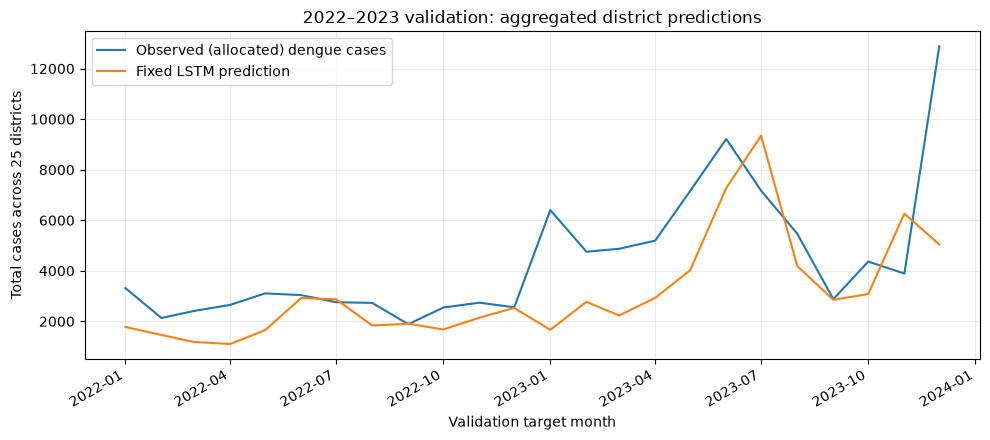

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(monthly_predictions["target_date"], monthly_predictions["actual_cases"], label="Observed (allocated) dengue cases")
ax.plot(monthly_predictions["target_date"], monthly_predictions["predicted_cases"], label="Fixed LSTM prediction")
ax.set(xlabel="Validation target month", ylabel="Total cases across 25 districts",
       title="2022–2023 validation: aggregated district predictions")
ax.legend(); ax.grid(alpha=0.25)
fig.autofmt_xdate(); fig.tight_layout()
fig.savefig(FIGURES_DIR / "notebook13_validation_monthly_predictions.png", dpi=160)
plt.show()


## Step 10 — Save the baseline and its provenance

We save a Keras `.keras` model, its hyperparameters, a validation prediction CSV, district error table, learning history and a metrics JSON.

These outputs allow Notebook 14 to compare a GWO-tuned model **against the exact fixed baseline**. No test metrics are saved because none have been computed.

In [11]:
model_path = MODELS_DIR / "notebook13_fixed_lstm_weather_only.keras"
model.save(model_path)
config_path = MODELS_DIR / "notebook13_fixed_lstm_config.json"
config_path.write_text(json.dumps({**CONFIG, "feature_names": names_train,
    "model_path": str(model_path.relative_to(PROJECT_ROOT))}, indent=2), encoding="utf-8")
metrics_path = METRICS_DIR / "notebook13_validation_metrics.json"
metrics_path.write_text(json.dumps({"dataset": VARIANT, "period": "2022-01_to_2023-12",
    "validation_only": True, "metrics": validation_metrics,
    "best_val_loss_log_mse": float(min(history.history["val_loss"])),
    "epochs_completed": len(history.history["loss"])}, indent=2), encoding="utf-8")
predictions.to_csv(TABLES_DIR / "notebook13_validation_predictions.csv", index=False)
district_metrics.to_csv(TABLES_DIR / "notebook13_validation_district_metrics.csv", index=False)
pd.DataFrame(history.history).to_csv(TABLES_DIR / "notebook13_training_history.csv", index=False)
for p in [model_path, config_path, metrics_path]: print("Saved:", p.relative_to(PROJECT_ROOT))
print("NOTEBOOK 13 COMPLETED — validation only; 2024 test untouched.")


Saved: models\notebook13_fixed_lstm_weather_only.keras
Saved: models\notebook13_fixed_lstm_config.json
Saved: results\metrics\notebook13_validation_metrics.json
NOTEBOOK 13 COMPLETED — validation only; 2024 test untouched.


## Research notes: what can we conclude?

**Supported after you run this notebook:** validation-period MAE/RMSE, whether the model overfits, which districts are hardest to predict, and a reproducible baseline configuration.

**Not yet supported:** 2024 generalization performance, superiority to published methods, causal effects of weather, or statistical significance of differences.

**Research limitation:** Six-month input windows overlap, so validation errors are not statistically independent. Also, a model trained across all districts without explicit district encoding may learn an average regional pattern rather than a district-specific one. The 2010–2024 weekly-to-monthly allocation creates estimated monthly dengue totals.

**Next:** Notebook 14 searches a **small, predefined** hyperparameter space with Grey Wolf Optimization. It will keep the same six-month input, 32-unit LSTM, 16-unit Dense layer, feature list, training/validation split, and loss function. It will not inspect the 2024 test set.
